In [ ]:
#ВАРИАНТ 2

In [88]:
# ========================== Задание 1. A/B–тестирование ==========================

In [ ]:
#1. Импорт библиотек и загрузка датасетов

In [43]:
# ==================== Импорт библиотек ==================== 
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from pathlib import Path

%matplotlib inline

In [44]:
# ==================== Составление файловых путей ==================== 
student_login = 'il-kobzev'  
way = f'/mnt/HC_Volume_18315164/home-jupyter/jupyter-{student_login}'

def collect_all_csv_paths(way):
    """Collect paths of all CSV files in the directory and subdirectories"""
    csv_paths = []
    for root, _, files in os.walk(way):
        for filename in files:
            if filename.endswith('.csv'):  # Filter only CSV files
                absolute_file_path = os.path.join(root, filename)
                csv_paths.append(absolute_file_path)
    return csv_paths

# ==================== Чтение датасетов из файлов ==================== 

csv_file_paths = collect_all_csv_paths(way)
print(f"Found {len(csv_file_paths)} CSV files:")
for path in csv_file_paths:
    print(f"  - {path}")

dataframes = {}
for csv_path in csv_file_paths:
    try:
        # Extract filename without extension
        filename = os.path.basename(csv_path)
        filename_without_ext = os.path.splitext(filename)[0]
        
        # Read CSV file
        df = pd.read_csv(csv_path)
        
        # Store dataframe with filename as key
        dataframes[filename_without_ext] = df
        
        # Create additional variable with filename as variable name
        # Replace special characters to make valid Python variable name
        var_name = filename_without_ext.replace('-', '_').replace(' ', '_').replace('.', '_')
        
        # Add to global namespace
        globals()[var_name] = df
        
        print(f"✓ Successfully read: {filename} (shape: {df.shape}) → available as: '{filename_without_ext}' in dataframes dict and as variable '{var_name}'")
        
    except Exception as e:
        print(f"✗ Error reading {os.path.basename(csv_path)}: {e}")


print(f"\nTotal DataFrames loaded: {len(dataframes)}")

# ==================== Подтверждение загрузки датафреймов ==================== 

print("\nAvailable DataFrames:")

for name, df in dataframes.items():
    print(f"  - {name}: {df.shape}")
df_groups = Проект_2_groups
df_checks = Проект_2_checks
df_active_studs = Проект_2_active_studs
df_group_add = Проект_2_group_add

Found 4 CSV files:
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Проект_2_active_studs.csv
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Проект_2_checks.csv
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Проект_2_group_add.csv
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Проект_2_groups.csv
✓ Successfully read: Проект_2_active_studs.csv (shape: (8341, 1)) → available as: 'Проект_2_active_studs' in dataframes dict and as variable 'Проект_2_active_studs'
✓ Successfully read: Проект_2_checks.csv (shape: (541, 1)) → available as: 'Проект_2_checks' in dataframes dict and as variable 'Проект_2_checks'
✓ Successfully read: Проект_2_group_add.csv (shape: (92, 2)) → available as: 'Проект_2_group_add' in dataframes dict and as variable 'Проект_2_group_add'
✓ Successfully read: Проект_2_groups.csv (shape: (74484, 1)) → available as: 'Проект_2_groups' in dataframes dict and as variable 'Проект_2_groups'

Total DataFrames loaded: 4

Available Data

In [9]:
# ==================== Сборка DF ==================== 

# ==================== DF 1 - Полный список студентов в группах в одном датафрейме (объединие df_groups и df_group_add)

# Create a new DataFrame from the original, keeping the original column

#создание копии оригинального df для избежания потери данных
df_groups1 = df_groups.copy()

# Разделение "слипшихся" столбцов id и grp

df_groups1[["id", "grp"]] = df_groups1['id;grp'].str.split(";", expand=True)


df_groups1["id"] = df_groups1["id"].astype("int64")

df_groups1["grp"] = df_groups1["grp"].astype("category")
df_groups1.head()
#df_groups1.columns
df_groups2 = df_groups1.drop(("id;grp"), axis='columns')
df_groups2
#df_groups2.dtypes
df_groups2.value_counts()

# Удаление дубликатов и пропусков

df_groups3 = df_groups2.drop_duplicates().dropna()

# Дубликаты и пропуски не обнаружены

df_groups3.value_counts()
df_group_add.value_counts()
df_group_add1 = df_group_add.drop_duplicates().dropna()
df_group_add1["id"].dtype
df_groups3["id"].dtype

# Объединение двух DF с группами студентов в один

df_groups_full = df_groups3.merge(df_group_add1, on=["id", "grp"], how='outer')

#######

df_groups_full = df_groups_full.rename(columns={'id': 'student_id'})
df_groups_full

# ==================== DF2 - чеки (revenue)

#создание копии оригинального df для избежания потери данных

df_checks1 = df_checks.copy()

# Разделение "слипшихся" столбцов id и grp
df_checks1[["student_id", "rev"]] = df_checks1['student_id;"rev"'].str.split(";", expand=True)

# Convert types
df_checks1["student_id"] = df_checks1["student_id"].astype("int64")
df_checks1["rev"] = df_checks1["rev"].astype("float")

#Получаем датафрейм с разделением и нормальными названиями колонок (df_checks_clean)
df_checks_ok = df_checks1.drop('student_id;"rev"', axis=1)
df_checks_ok


# ==================== DF3 - Активные УЗ студентов на момент эксперимента (подходит для работы в первозданном виде)

df_active_studs

,student_id
0,581585
1,5723133
2,3276743
3,4238589
4,4475369
...,...
8336,1794344
8337,296883
8338,3598448
8339,3610547


In [ ]:
# 2. Изучение собранных DF

In [ ]:
# df_active_studs

In [45]:
df_active_studs.head()

,student_id
0,581585
1,5723133
2,3276743
3,4238589
4,4475369


In [46]:
df_active_studs.describe()

,student_id
count,8.341000e+03
mean,2.448547e+06
std,1.564978e+06
min,1.627000e+03
25%,1.118405e+06
50%,2.094192e+06
75%,3.638877e+06
max,5.951797e+06


In [47]:
df_active_studs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8341 entries, 0 to 8340
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   student_id  8341 non-null   int64
dtypes: int64(1)
memory usage: 65.3 KB


In [48]:
df_active_studs.dtypes

student_id    int64
dtype: object

In [14]:
# df_groups_full

In [50]:
df_groups_full.head()

,student_id,grp
0,1489,B
1,1627,A
2,1768,B
3,1783,B
4,1794,A


In [51]:
df_groups_full.describe()

,student_id
count,7.457600e+04
mean,2.165617e+06
std,2.786959e+06
min,1.489000e+03
25%,9.197188e+05
50%,1.669752e+06
75%,3.328121e+06
max,2.010677e+08


In [52]:
df_groups_full.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 74576 entries, 0 to 74575
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   student_id  74576 non-null  int64 
 1   grp         74576 non-null  object
dtypes: int64(1), object(1)
memory usage: 1.7+ MB


In [53]:
df_groups_full.dtypes

student_id     int64
grp           object
dtype: object

In [29]:
# df_checks_ok

In [54]:
df_checks_ok.head()

,student_id,rev
0,1627,990.0
1,3185,690.0
2,25973,690.0
3,26280,690.0
4,100300,990.0


In [55]:
df_checks_ok.describe()

,student_id,rev
count,5.410000e+02,541.000000
mean,2.514772e+06,1059.752317
std,1.726839e+06,762.712359
min,1.627000e+03,199.000000
25%,9.871290e+05,290.000000
50%,2.526021e+06,840.000000
75%,3.993249e+06,1900.000000
max,5.740903e+06,4650.000000


In [56]:
df_checks_ok.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_id  541 non-null    int64  
 1   rev         541 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 8.6 KB


In [57]:
df_checks_ok.dtypes

student_id      int64
rev           float64
dtype: object

In [ ]:
# Вывод - форматы данных ок, дубликаты сброшены при создании df

In [58]:
# Проверка выборок на аномалии
#Проверка наличия УЗ (student_id), которые есть в df с оплатой, но нет в df с активными УЗ
studs_anomaly = df_groups_full[
    ~df_groups_full['student_id'].isin(df_active_studs['student_id']) & 
    df_groups_full['student_id'].isin(df_checks_ok['student_id'])
]

print(f"Найдено {len(studs_anomaly)} student_id, не являющихся активными, но, при этом - оплатившими:")
studs_anomaly.head()

# Если нужны только ID
#studs_anomaly_ids = studs_anomaly['student_id']

Найдено 149 student_id, не являющихся активными, но, при этом - оплатившими:


,student_id,grp
39,3185,B
121,25973,B
125,26280,B
223,100645,B
254,102534,B


In [ ]:
#Удаление аномальных id из checks - оставляем только актуальные записи об оплате

In [59]:
# Удаляем записи, чьи student_id есть в studs_anomaly
df_checks_clean = df_checks_ok[~df_checks_ok['student_id'].isin(studs_anomaly['student_id'])]

print(f"Было записей: {len(df_checks_ok)}")
print(f"Стало записей: {len(df_checks_clean)}")
print(f"Удалено записей: {len(df_checks_ok) - len(df_checks_clean)}")
print("\nОтфильтрованный датафрейм:")
print(df_checks_clean.head())

Было записей: 541
Стало записей: 392
Удалено записей: 149

Отфильтрованный датафрейм:
    student_id        rev
0         1627   990.0000
4       100300   990.0000
8       108270   290.0000
26      264473  1900.0001
27      274352   690.0000


In [60]:
# 3. Объединение df по группам в один общий
df_studsall = pd.merge(df_active_studs,df_groups_full, on = "student_id", how="inner")
# анализ значений и типов данных в новом df
df_studsall['grp'].value_counts()

B    6803
A    1538
Name: grp, dtype: int64

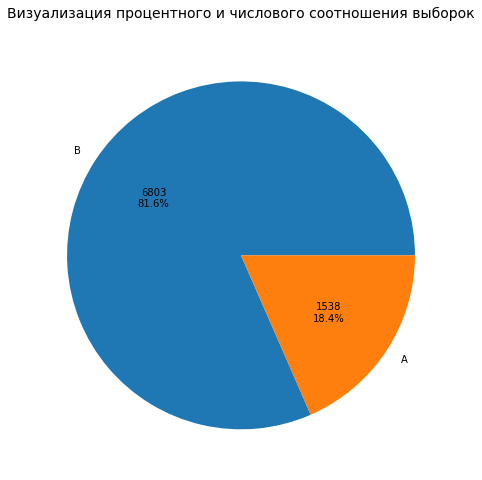

In [61]:
#Визуализация процентного и числового соотношения выборок групп студентов
a = df_studsall['grp'].value_counts()
total = sum(a.values)

plt.figure(figsize=(10, 8))
wedges, texts, autotexts = plt.pie(a.values, 
                                    labels=a.index, 
                                    autopct='%1.1f%%')

# Меняем текст автоподписей
for i, (pct, val) in enumerate(zip([p.get_text() for p in autotexts], a.values)):
    autotexts[i].set_text(f'{val}\n{pct}')

plt.title('Визуализация процентного и числового соотношения выборок', fontsize=14, pad=20)
plt.show()

In [ ]:
# Вывод - в выборках число студентов отличается в 5 раз

In [ ]:
# 4. Делаем равное количество студентов в обеих выборках для чистоты A\B теста

In [62]:
#Определение выборок
count_A = df_studsall[df_studsall['grp'] == 'A'].shape[0]
count_B = df_studsall[df_studsall['grp'] == 'B'].shape[0]
#Уменьшение выборки B c рандомизацией содердимого
df_B = df_studsall[df_studsall['grp'] == 'B'].sample(count_A, random_state=42)
df_studsall_cutb = pd.concat([df_studsall[df_studsall['grp'] == 'A'], df_B])
#новый df с подгонкой выборок 1:1 по числу записей 
df_studsall_cutb = df_studsall_cutb.sample(frac=1, random_state=42).reset_index(drop=True)
print(df_studsall_cutb)

      student_id grp
0         994672   A
1        4938489   A
2         651659   B
3        1146366   B
4        2252804   A
...          ...  ..
3071     1057924   B
3072     3577257   A
3073     1709928   A
3074      638417   A
3075     1064583   A

[3076 rows x 2 columns]


Text(0.5, 1.0, 'Визуализация обеспеченного соответствия размеров выборок')

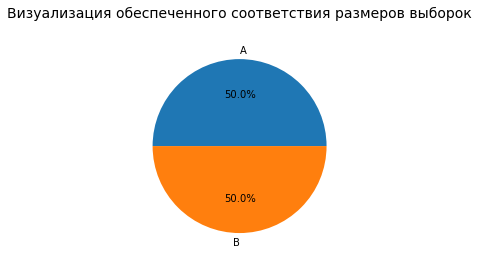

In [63]:
# Визуализация подогнанного
countdf = df_studsall_cutb['grp'].value_counts()
plt.pie(countdf.values, labels=countdf.index, autopct='%1.1f%%')
plt.show
plt.title('Визуализация обеспеченного соответствия размеров выборок', fontsize=14, pad=20)

In [ ]:
# 5. Присоединение датафрейма с чеками (revenue) к df с выборками студентов

In [26]:
df_studchecks = pd.merge(df_studsall_cutb, df_checks_clean, on = "student_id", how = "inner")
df_studchecks

,student_id,grp,rev
0,967564,A,580.0000
1,3249082,B,990.0000
2,3319672,B,1968.0000
3,1008928,B,1900.0001
4,1590279,A,1530.0000
...,...,...,...
134,1335384,B,840.0000
135,1820232,B,1729.0000
136,4934549,B,840.0000
137,3369713,A,590.0000


In [27]:
df_studchecks.head()

,student_id,grp,rev
0,967564,A,580.0000
1,3249082,B,990.0000
2,3319672,B,1968.0000
3,1008928,B,1900.0001
4,1590279,A,1530.0000


In [ ]:
# Первичный анализ нового DF

In [28]:
df_studchecks.describe

<bound method NDFrame.describe of      student_id grp        rev
0        967564   A   580.0000
1       3249082   B   990.0000
2       3319672   B  1968.0000
3       1008928   B  1900.0001
4       1590279   A  1530.0000
..          ...  ..        ...
134     1335384   B   840.0000
135     1820232   B  1729.0000
136     4934549   B   840.0000
137     3369713   A   590.0000
138     5177600   A   199.0000

[139 rows x 3 columns]>

In [29]:
df_studchecks.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 139 entries, 0 to 138
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_id  139 non-null    int64  
 1   grp         139 non-null    object 
 2   rev         139 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 4.3+ KB


In [30]:
df_studchecks.dtypes

student_id      int64
grp            object
rev           float64
dtype: object

In [ ]:
#================================================================================================================

In [ ]:
# 6. Анализ и графики по новому датафрейму

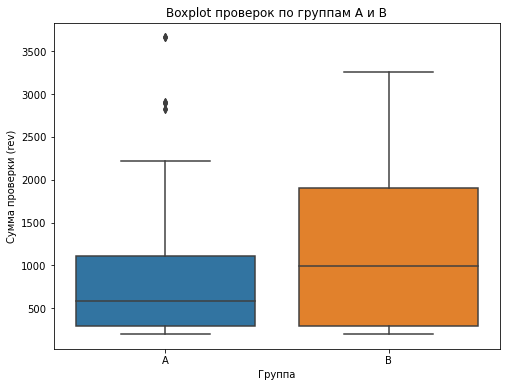

In [31]:
# Строим boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(x='grp', y='rev', data=df_studchecks)
plt.title('Boxplot проверок по группам A и B')
plt.xlabel('Группа')
plt.ylabel('Сумма проверки (rev)')
plt.show()

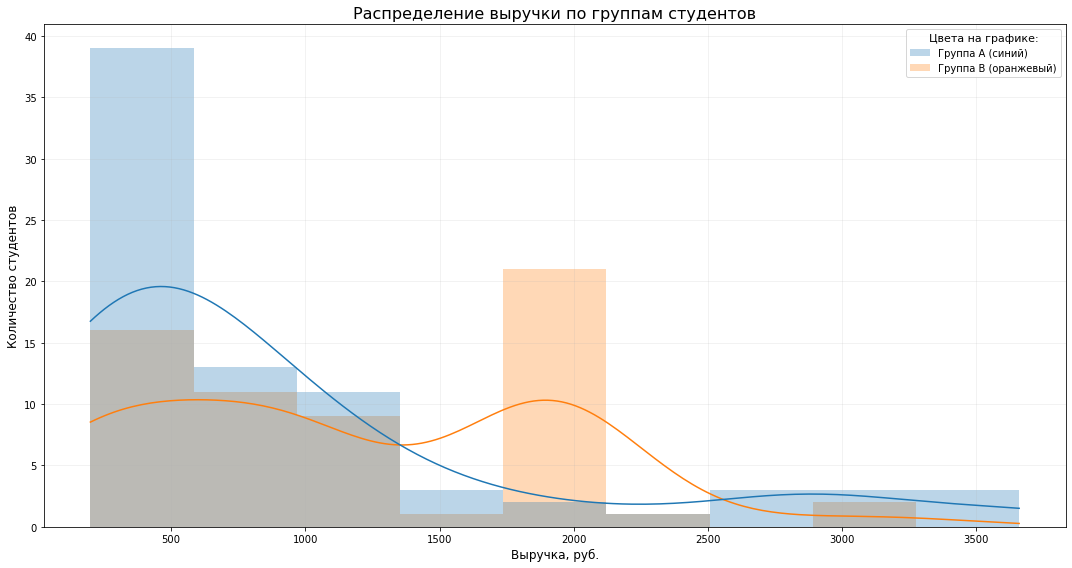

In [64]:
# B гистограмму с KDE
fig, ax = plt.subplots(figsize=(15, 8))

# Строим гистограмму с KDE, где KDE масштабирована под количество
sns.histplot(data=df_studchecks, x="rev", hue="grp", 
             kde=True,  # Включаем KDE
             stat="count",  # Показываем количество
             common_norm=False,  # Каждая группа нормируется отдельно
             alpha=0.3, 
             element="step",  # Более чистый вид гистограммы
             linewidth=0)

plt.title('Распределение выручки по группам студентов', fontsize=16)
plt.xlabel('Выручка, руб.', fontsize=12)
plt.ylabel('Количество студентов', fontsize=12)

# Создаем кастомную легенду с пояснениями цветов
from matplotlib.patches import Patch

# Определяем цвета (seaborn использует свою палитру по умолчанию)
legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.3, label='Группа A (синий)'),
    Patch(facecolor='tab:orange', alpha=0.3, label='Группа B (оранжевый)')
]

plt.legend(handles=legend_elements, title='Цвета на графике:', 
           fontsize=10, title_fontsize=11)

plt.grid(alpha=0.2, linestyle='-')

plt.tight_layout()
plt.show()

In [33]:
# Считаем Распределение в числовом виде
df_studchecks[df_studchecks['grp'] == 'B'].rev.value_counts(bins=10).head(3)

(1729.5, 2035.6]    20
(195.938, 505.1]    16
(811.2, 1117.3]     12
Name: rev, dtype: int64

In [ ]:
#График дисперсии

In [57]:
# Выводы
# 1) Распределение далеко от нормального
# 2) У многих пользователей покупки лежат в диапазоне от 1500+ до 2500 
# 3) + много низких чеков до 1000


In [72]:
# ===============================================================================================================
# 7 ДИСПЕРСИЯ

In [70]:
# Дисперсия для чеков
disp_checks = np.var(df_studchecks['rev'], ddof=0)
print(f"Генральная дисперсия по платежам (ddof=0): {disp_checks:.2f}")

Генральная дисперсия по платежам (ddof=0): 742043.82


In [ ]:
# Вывод по дисперсии для чеков
# Группа A вносит больший вклад в общий разброс, чем группа B

In [68]:
# Дисперсия по группам

var_A_np = np.var(df_studchecks[df_studchecks['grp'] == 'A']['rev'], ddof=1)
var_B_np = np.var(df_studchecks[df_studchecks['grp'] == 'B']['rev'], ddof=1)
print(f"\nГруппа A: {var_A_np:.2f}, Группа B: {var_B_np:.2f}")


Группа A: 846276.19, Группа B: 597043.13


In [69]:
# Вывод по дисперсии для групп:
# 1) Группа А: Большая дисперсия → Больше разнообразие студентов → Больше неопределенность
# 2) Группа Б: Меньшая дисперсия → Больше однородность → Легче прогнозировать
# Разнообразие в контрольной группе выше, в целевой - ниже, что указывает на стабильный результат для целевой группы.
# Необходимо понять, насколько стабильность в целевой группе - это хорошо...

In [37]:
# для стандартного отклонения:

# NumPy (нужно указать ddof=1)
disp_std = np.std(df_studchecks['rev'], ddof=1)
print(f"Стандартное отклонение (ddof=1): {disp_std:.2f}")

Стандартное отклонение (ddof=1): 864.54


In [ ]:
# Вывод по стандартному отклонению с точки зрения чеков:
# 1) Разброс значений выручки очень велик (скорее всего CV > 50%)
# 2) Участники групп могут отличаться по платежеспособности

In [ ]:
# ОБЩИЙ ВЫВОД ПО ДИСПЕРСИИ:
'''
"Студенты делятся на два принципиально разных сегмента: 
- неоднородную группу A с высоким потенциалом, но высоким риском, 
- и однородную группу B с предсказуемой стабильностью, требующих разных бизнес-стратегий."
'''

In [66]:
# Создаем таблицу по дисперсии
summary_table = df_studchecks.groupby('grp')['rev'].agg([
    ('Количество', 'count'),
    ('Среднее', 'mean'),
    ('Медиана', 'median'),
    ('Дисперсия', 'var'),
    ('Стд. отклонение', 'std'),
    ('Минимум', 'min'),
    ('Максимум', 'max'),
    ('Размах', lambda x: x.max() - x.min())
])

print("СВОДНАЯ ТАБЛИЦА СТАТИСТИК:")
print("=" * 80)
print(summary_table.round(2))
print("=" * 80)


СВОДНАЯ ТАБЛИЦА СТАТИСТИК:
     Количество  Среднее  Медиана  Дисперсия  Стд. отклонение  Минимум  \
grp                                                                      
A            78   933.59    585.0  846276.19           919.93    199.0   
B            61  1184.69    990.0  597043.13           772.69    199.0   

     Максимум  Размах  
grp                    
A      3660.0  3461.0  
B      3260.0  3061.0  


In [76]:
# Составляем функцию для расчета набора метрик.
def calculate_metrics(group):
    from scipy import stats
    import numpy as np
    
    return pd.Series({
        'count': group.count(),
        'mean': group.mean(),
        'median': group.median(),
        'std': group.std(),
        'sem': group.sem(),  # стандартная ошибка среднего
        'sum': group.sum(),
        'min': group.min(),
        'max': group.max(),
        'q25%': group.quantile(0.25),
        'q75%': group.quantile(0.75),
        'iqr': group.quantile(0.75) - group.quantile(0.25),  # межквартильный размах
        'cv': (group.std() / group.mean() * 100 if group.mean() != 0 else np.nan),  # коэффициент вариации %
        'skew': group.skew(),  # коэффициент асимметрии
        'missing_values': group.isnull().sum()  # количество пропущенных значений
    })

# Применяем функцию
detailed_stats = df_studchecks.groupby('grp')['rev'].apply(calculate_metrics).unstack().round(2)
print(detailed_stats)

     count     mean  median     std     sem      sum    min     max   q25%  \
grp                                                                          
A     78.0   933.59   585.0  919.93  104.16  72820.0  199.0  3660.0  290.0   
B     61.0  1184.69   990.0  772.69   98.93  72266.0  199.0  3260.0  290.0   

        q75%      iqr     cv  skew  missing_values  
grp                                                 
A    1114.75   824.75  98.54  1.71             0.0  
B    1900.00  1610.00  65.22  0.36             0.0  


In [79]:
# Считаем  и проверяем размер групп
group_A = df_studchecks[df_studchecks['grp'] == 'A']['rev']
group_B = df_studchecks[df_studchecks['grp'] == 'B']['rev']

print(f"Размер группы A: {len(group_A)}")
print(f"Размер группы B: {len(group_B)}")

Размер группы A: 78
Размер группы B: 61


<Figure size 864x432 with 0 Axes>

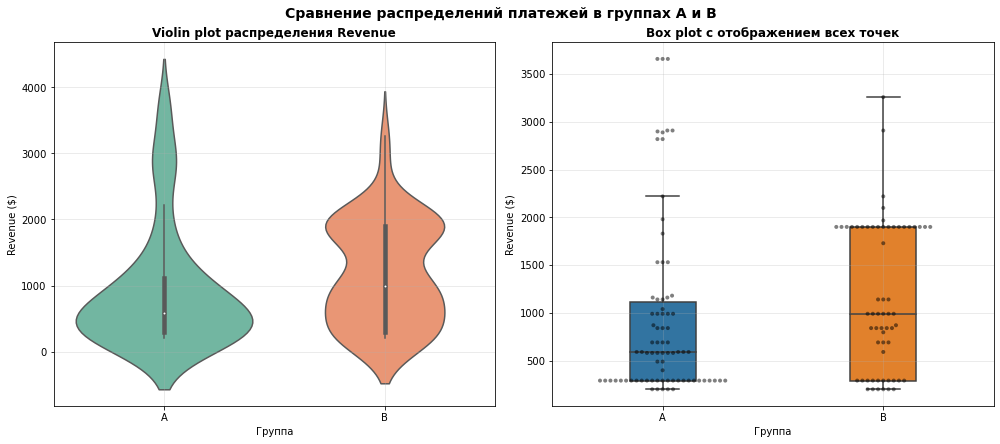

In [88]:
# Комбинированный график: Boxplot внутри Violin plot
plt.figure(figsize=(12, 6))

# Создаем подграфики
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# 1. Violin plot с boxplot внутри
sns.violinplot(x='grp', y='rev', data=df_studchecks, 
               inner='box', palette='Set2', ax=ax1)
ax1.set_title('Violin plot распределения Revenue', fontsize=12, fontweight='bold')
ax1.set_xlabel('Группа')
ax1.set_ylabel('Revenue ($)')
ax1.grid(True, alpha=0.3)

# 2. Swarm plot + Box plot
sns.boxplot(x='grp', y='rev', data=df_studchecks, 
            width=0.3, ax=ax2, showfliers=False)
sns.swarmplot(x='grp', y='rev', data=df_studchecks, 
              color='black', alpha=0.5, size=4, ax=ax2)
ax2.set_title('Box plot с отображением всех точек', fontsize=12, fontweight='bold')
ax2.set_xlabel('Группа')
ax2.set_ylabel('Revenue ($)')
ax2.grid(True, alpha=0.3)

plt.suptitle('Сравнение распределений платежей в группах A и B', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [84]:
# ===============================================================================================================

In [ ]:
# 8 ПЕРЕМЕННЫЕ И ГИПОТЕЗЫ

In [ ]:
# Выбор переменных
# Ключевая переменная 1 - rev (выручка)
'''
* Главная бизнес-метрика, по которой уже есть расчёты дисперсии и статистики
* Непрерывная количественная переменная

'''
# Группирующая переменная 2 - grp (группа A/B)
'''
* Ключевой сегмент для сравнения + уже есть статистика по группам
* Категориальная (бинарная) переменная
'''


In [ ]:
# Формулировка гипотезp по этим переменным:

In [92]:
# H0 (Нулевая гипотеза): 

## Распределение выручки на одного активного пользователя (ARPU) в группе A и группе B является одинаковым.
# Продуктовая интерпретация H0:

## Внесённое изменение (фича, интервенция в группе B) не оказало никакого влияния

# H1 (Альтернативная гипотеза):
## Распределение выручки на одного активного пользователя (ARPU) в группе A и группе B является различным.
# Продуктовая интерпретация H1: 
## Внесённое изменение статистически значимо изменило картину платежей среди активных пользователей.

In [ ]:
# Проводим тест Колмогорова - Смирнова

In [95]:
# ТЕСТ КОЛМОГОРОВА-СМИРНОВА
print("=" * 60)
print("ТЕСТ КОЛМОГОРОВА-СМИРНОВА")
print("=" * 60)

# Выполняем тест
ks_statistic, p_value = stats.ks_2samp(group_A, group_B)

print(f"Статистика D (макс. разница между ECDF): {ks_statistic:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"P-value (научная нотация): {p_value:.2e}")

# Критическое значение D для α=0.05
n1, n2 = len(group_A), len(group_B)
alpha = 0.05
D_critical = 1.36 * np.sqrt((n1 + n2) / (n1 * n2))  # Приближенная формула

print(f"\nКритическое значение D для α={alpha}: {D_critical:.4f}")
print(f"Фактическое D: {ks_statistic:.4f}")

# Интерпретация
if ks_statistic > D_critical:
    print("✓ D > D_critical: ОТКЛОНЯЕМ H₀")
else:
    print("✗ D ≤ D_critical: НЕ ОТКЛОНЯЕМ H₀")

if p_value < 0.05:
    print(f"✓ P-value ({p_value:.4f}) < 0.05: ОТКЛОНЯЕМ H₀")
    print("\nВЫВОД: Распределения выручки в группах A и B СТАТИСТИЧЕСКИ ЗНАЧИМО РАЗЛИЧАЮТСЯ")
else:
    print(f"✗ P-value ({p_value:.4f}) ≥ 0.05: НЕ ОТКЛОНЯЕМ H₀")
    print("\nВЫВОД: Нет оснований считать, что распределения различаются")

ТЕСТ КОЛМОГОРОВА-СМИРНОВА
Статистика D (макс. разница между ECDF): 0.2875
P-value: 0.005251
P-value (научная нотация): 5.25e-03

Критическое значение D для α=0.05: 0.2325
Фактическое D: 0.2875
✓ D > D_critical: ОТКЛОНЯЕМ H₀
✓ P-value (0.0053) < 0.05: ОТКЛОНЯЕМ H₀

ВЫВОД: Распределения выручки в группах A и B СТАТИСТИЧЕСКИ ЗНАЧИМО РАЗЛИЧАЮТСЯ


In [ ]:
# Визуализация

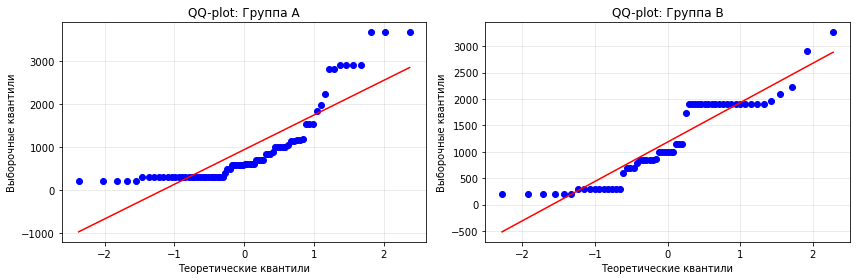


ИНТЕРПРЕТАЦИЯ Q-Q PLOT:
• Точки на прямой линии = распределение близко к нормальному
• Точки выше прямой = хвост распределения тяжелее нормального
• Точки ниже прямой = хвост распределения легче нормального

• Группа A (скошенность 1.71): точки сильно отклоняются от прямой
• Группа B (скошенность 0.36): точки ближе к прямой линии


In [102]:
# Q-Q plot для проверки нормальности распределений
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Q-Q plot для группы A
stats.probplot(group_A, dist="norm", plot=axes[0])
axes[0].set_title('QQ-plot: Группа A')
axes[0].set_xlabel('Теоретические квантили')
axes[0].set_ylabel('Выборочные квантили')
axes[0].grid(True, alpha=0.3)

# Q-Q plot для группы B
stats.probplot(group_B, dist="norm", plot=axes[1])
axes[1].set_title('QQ-plot: Группа B')
axes[1].set_xlabel('Теоретические квантили')
axes[1].set_ylabel('Выборочные квантили')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Краткая интерпретация
print("\n" + "=" * 60)
print("ИНТЕРПРЕТАЦИЯ Q-Q PLOT:")
print("=" * 60)
print("• Точки на прямой линии = распределение близко к нормальному")
print("• Точки выше прямой = хвост распределения тяжелее нормального")
print("• Точки ниже прямой = хвост распределения легче нормального")
print("\n• Группа A (скошенность 1.71): точки сильно отклоняются от прямой")
print("• Группа B (скошенность 0.36): точки ближе к прямой линии")

In [ ]:
# ИТОГОВЫЙ ОТЧЕТ

In [108]:
print("\n" + "=" * 60)
print("ИТОГОВЫЙ ОТЧЕТ")
print("=" * 60)

print(f"\nГИПОТЕЗЫ:")
print(f"H₀: Распределения ARPU в группах A и B одинаковы")
print(f"H₁: Распределения ARPU в группах A и B различны")

print(f"\nРЕЗУЛЬТАТЫ:")
print(f"• KS-тест: D = {ks_statistic:.4f}, p = {p_value:.4f}")
print(f"• Статистическая значимость: {'ЕСТЬ (p < 0.05)' if p_value < 0.05 else 'НЕТ (p ≥ 0.05)'}")

print(f"\nПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ:")
print(f"• Средняя выручка: Группа B > A на {group_B.mean() - group_A.mean():.0f} ({group_B.mean()/group_A.mean()*100:.0f}%)")
print(f"• Медианная выручка: Группа B > A на {group_B.median() - group_A.median():.0f} ({group_B.median()/group_A.median()*100:.0f}%)")
print(f"• Изменение формы распределения: Скошенность уменьшилась с {group_A.skew():.2f} до {group_B.skew():.2f}")



ИТОГОВЫЙ ОТЧЕТ

ГИПОТЕЗЫ:
H₀: Распределения ARPU в группах A и B одинаковы
H₁: Распределения ARPU в группах A и B различны

РЕЗУЛЬТАТЫ:
• KS-тест: D = 0.2875, p = 0.0053
• Статистическая значимость: ЕСТЬ (p < 0.05)

ПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ:
• Средняя выручка: Группа B > A на 251 (127%)
• Медианная выручка: Группа B > A на 405 (169%)
• Изменение формы распределения: Скошенность уменьшилась с 1.71 до 0.36


In [ ]:
# ========================================================================================================

In [ ]:
# 9 ВЫБОР И РАСЧЕТ МЕТРИК

In [91]:
## В связи с тем, что представленные датасеты содержат в себе данные маркетингового типа,
##    связанные с анализом пользовательской активности и оплаты сайта с онлайн курсами,
##    лучшим выбором метрик будут следующие метрики:
# 1) Выручка (Revenue) - общий параметр выручки
# 2) Средняя выручка на пользователя (ARPU) - для того, чтобы удостовериться, что в целевой группе (B) действительно платят больше
# 3) Медианная выручка на пользователя - еще один способ удостовериться, что в целевой группе (B) действительно платят больше

'\nВ связи с тем, что представленные датасеты содержат в себе данные маркетингового типа,\n    связанные с анализом пользовательской активности и оплаты сайта с онлайн курсами,\n    лучшим выбором метрик будут следующие метрики:\n'

In [ ]:
# Рассчеты по выбранным метрикам

In [109]:
# Размеры групп
print(f"Размер групп:")
print(f"  Группа A: {len(group_A)} пользователей")
print(f"  Группа B: {len(group_B)} пользователей")

# Основные метрики выручки
print(f"\n1. Выручка (Revenue):")
print(f"  Группа A: {group_A.sum():.0f}")
print(f"  Группа B: {group_B.sum():.0f}")
print(f"  Разница: {group_B.sum() - group_A.sum():.0f} ({((group_B.sum()/group_A.sum())-1)*100:+.1f}%)")

print(f"\n2. Средняя выручка на пользователя (ARPU):")
print(f"  Группа A: {group_A.mean():.1f}")
print(f"  Группа B: {group_B.mean():.1f}")
print(f"  Разница: {group_B.mean() - group_A.mean():.1f} ({((group_B.mean()/group_A.mean())-1)*100:+.1f}%)")

print(f"\n3. Медианная выручка на пользователя:")
print(f"  Группа A: {group_A.median():.1f}")
print(f"  Группа B: {group_B.median():.1f}")
print(f"  Разница: {group_B.median() - group_A.median():.1f} ({((group_B.median()/group_A.median())-1)*100:+.1f}%)")

Размер групп:
  Группа A: 78 пользователей
  Группа B: 61 пользователей

1. Выручка (Revenue):
  Группа A: 72820
  Группа B: 72266
  Разница: -554 (-0.8%)

2. Средняя выручка на пользователя (ARPU):
  Группа A: 933.6
  Группа B: 1184.7
  Разница: 251.1 (+26.9%)

3. Медианная выручка на пользователя:
  Группа A: 585.0
  Группа B: 990.0
  Разница: 405.0 (+69.2%)


In [ ]:
# Визуализация метрик

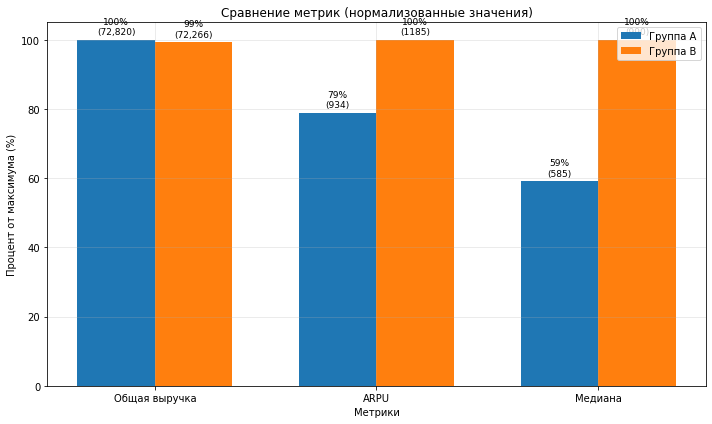

In [118]:
fig, ax = plt.subplots(figsize=(10, 6))

# Нормализуем каждую метрику отдельно
metrics = ['Общая выручка', 'ARPU', 'Медиана']
max_vals = [max(group_A.sum(), group_B.sum()), 
           max(group_A.mean(), group_B.mean()), 
           max(group_A.median(), group_B.median())]

# Преобразуем в проценты от максимума
group_a_norm = [group_A.sum()/max_vals[0]*100, 
               group_A.mean()/max_vals[1]*100, 
               group_A.median()/max_vals[2]*100]

group_b_norm = [group_B.sum()/max_vals[0]*100, 
               group_B.mean()/max_vals[1]*100, 
               group_B.median()/max_vals[2]*100]

x = np.arange(len(metrics))
width = 0.35

bars1 = ax.bar(x - width/2, group_a_norm, width, label='Группа A', color='#1f77b4')
bars2 = ax.bar(x + width/2, group_b_norm, width, label='Группа B', color='#ff7f0e')

# Настройки графика
ax.set_xlabel('Метрики')
ax.set_ylabel('Процент от максимума (%)')
ax.set_title('Сравнение метрик (нормализованные значения)')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.grid(True, alpha=0.3)

# Добавляем значения - показываем и проценты, и реальные значения
for i, (a_norm, b_norm, a_val, b_val) in enumerate(zip(group_a_norm, group_b_norm, group_a_vals, group_b_vals)):
    # Для группы A
    ax.text(i - width/2, a_norm + 1, 
            f'{a_norm:.0f}%\n({a_val:,.0f})' if i == 0 else f'{a_norm:.0f}%\n({a_val:.0f})',
            ha='center', va='bottom', fontsize=9)
    # Для группы B
    ax.text(i + width/2, b_norm + 1, 
            f'{b_norm:.0f}%\n({b_val:,.0f})' if i == 0 else f'{b_norm:.0f}%\n({b_val:.0f})',
            ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# Дополнительная проверка распределения и стабильности

In [110]:
print(f"\n4. Разброс значений (стандартное отклонение):")
print(f"  Группа A: {group_A.std():.1f}")
print(f"  Группа B: {group_B.std():.1f}")
print(f"  Комментарий: {'Более стабильные траты в группе B' if group_B.std() < group_A.std() else 'Более стабильные траты в группе A'}")

print(f"\n5. Относительный разброс (коэффициент вариации, CV):")
print(f"  Группа A: {(group_A.std()/group_A.mean()*100):.1f}%")
print(f"  Группа B: {(group_B.std()/group_B.mean()*100):.1f}%")

print(f"\n6. Скошенность распределения:")
print(f"  Группа A: {group_A.skew():.2f} {'(сильная правосторонняя скошенность)' if group_A.skew() > 1 else ''}")
print(f"  Группа B: {group_B.skew():.2f} {'(близко к нормальному)' if abs(group_B.skew()) < 0.5 else ''}")


4. Разброс значений (стандартное отклонение):
  Группа A: 919.9
  Группа B: 772.7
  Комментарий: Более стабильные траты в группе B

5. Относительный разброс (коэффициент вариации, CV):
  Группа A: 98.5%
  Группа B: 65.2%

6. Скошенность распределения:
  Группа A: 1.71 (сильная правосторонняя скошенность)
  Группа B: 0.36 (близко к нормальному)


In [ ]:
# Сегментируем по уровню трат

In [111]:
# Определяем пороги для сегментации
low_threshold = group_A.quantile(0.25)  # Нижние 25%
high_threshold = group_A.quantile(0.75)  # Верхние 25%

print(f"\n7. Сегментация пользователей по уровню трат:")
print(f"  Пороги: низкие < {low_threshold:.0f}, средние, высокые > {high_threshold:.0f}")

# Считаем доли по сегментам
for group_name, group_data in [("A", group_A), ("B", group_B)]:
    total = len(group_data)
    low = (group_data <= low_threshold).sum()
    medium = ((group_data > low_threshold) & (group_data <= high_threshold)).sum()
    high = (group_data > high_threshold).sum()
    
    print(f"\n  Группа {group_name}:")
    print(f"    Низкие траты: {low} чел. ({low/total*100:.1f}%)")
    print(f"    Средние траты: {medium} чел. ({medium/total*100:.1f}%)")
    print(f"    Высокие траты: {high} чел. ({high/total*100:.1f}%)")


7. Сегментация пользователей по уровню трат:
  Пороги: низкие < 290, средние, высокые > 1115

  Группа A:
    Низкие траты: 30 чел. (38.5%)
    Средние траты: 28 чел. (35.9%)
    Высокие траты: 20 чел. (25.6%)

  Группа B:
    Низкие траты: 16 чел. (26.2%)
    Средние траты: 17 чел. (27.9%)
    Высокие траты: 28 чел. (45.9%)


In [ ]:
# ====================================================================================================================

In [ ]:
# 10 ПРИНИМАЕМ РЕШЕНИЕ

In [113]:
# Расчет дополнительных бизнес-метрик
print(f"\n" + "=" * 60)
print("МЕТРИКИ ДЛЯ ПРИНЯТИЯ БИЗНЕС-РЕШЕНИЙ")
print("=" * 60)

# Прирост в абсолютных числах
absolute_gain = group_B.sum() - group_A.sum()
relative_gain = ((group_B.sum()/group_A.sum())-1)*100

print(f"\n1. Абсолютный прирост выручки:")
print(f"  Группа B приносит на {absolute_gain:.0f} больше, чем A")
print(f"  Это {relative_gain:+.1f}% к текущему уровню")

# Оценка масштабирования
print(f"\n2. Прогноз при масштабировании на всех пользователей:")

print(f"\n3. Изменение структуры монетизации:")
print(f"  В группе A: {group_A.skew():.2f} скошенность → зависимость от небольшого числа 'китов'")
print(f"  В группе B: {group_B.skew():.2f} скошенность → более равномерное распределение доходов")
print(f"  Вывод: {'Более устойчивая модель монетизации **ОБНАРУЖЕНА В ГРУППЕ B**' if abs(group_B.skew()) < abs(group_A.skew()) else ''}")


МЕТРИКИ ДЛЯ ПРИНЯТИЯ БИЗНЕС-РЕШЕНИЙ

1. Абсолютный прирост выручки:
  Группа B приносит на -554 больше, чем A
  Это -0.8% к текущему уровню

2. Прогноз при масштабировании на всех пользователей:

3. Изменение структуры монетизации:
  В группе A: 1.71 скошенность → зависимость от небольшого числа 'китов'
  В группе B: 0.36 скошенность → более равномерное распределение доходов
  Вывод: Более устойчивая модель монетизации **ОБНАРУЖЕНА В ГРУППЕ B**


In [ ]:
# 11 ФИНАЛЬНЫЙ ОТЧЕТ

In [122]:
print(f"\n" + "=" * 60)
print("ИТОГОВАЯ СВОДКА И РЕКОМЕНДАЦИИ")
print("=" * 60)

# Сводная таблица
summary_data = {
    'Метрика': ['Выручка общая', 'ARPU', 'Медиана', 'Стандартное отклонение', 'Коэф. вариации', 'Скошенность'],
    'Группа A': [
        f"{group_A.sum():.0f}",
        f"{group_A.mean():.1f}",
        f"{group_A.median():.0f}",
        f"{group_A.std():.1f}",
        f"{group_A.std()/group_A.mean()*100:.1f}%",
        f"{group_A.skew():.2f}"
    ],
    'Группа B': [
        f"{group_B.sum():.0f}",
        f"{group_B.mean():.1f}",
        f"{group_B.median():.0f}",
        f"{group_B.std():.1f}",
        f"{group_B.std()/group_B.mean()*100:.1f}%",
        f"{group_B.skew():.2f}"
    ],
    'Изменение': [
        f"{((group_B.sum()/group_A.sum())-1)*100:+.1f}%",
        f"{((group_B.mean()/group_A.mean())-1)*100:+.1f}%",
        f"{((group_B.median()/group_A.median())-1)*100:+.1f}%",
        f"{((group_B.std()/group_A.std())-1)*100:+.1f}%",
        f"{((group_B.std()/group_B.mean())/(group_A.std()/group_A.mean())-1)*100:+.1f}%",
        f"{group_B.skew() - group_A.skew():+.2f}"
    ]
}

# Простой вывод таблицы
print("\nСводная таблица метрик:")
print("-" * 70)
print(f"{'Метрика':<25} {'Группа A':<15} {'Группа B':<15} {'Изменение':<15}")
print("-" * 70)

for i in range(len(summary_data['Метрика'])):
    print(f"{summary_data['Метрика'][i]:<25} {summary_data['Группа A'][i]:<15} {summary_data['Группа B'][i]:<15} {summary_data['Изменение'][i]:<15}")

print("-" * 70)

# Рекомендация
print(f"\nРЕКОМЕНДАЦИЯ:")

if p_value < 0.05 and group_B.mean() > group_A.mean():
    print("✓ Изменение в группе B показало статистически значимое улучшение")
    print("✓ ARPU вырос на {:.1f}%".format(((group_B.mean()/group_A.mean())-1)*100))
    print("✓ !!! РЕКОМЕНДУЕТСЯ ВНЕДРИТЬ ИЗМЕНЕНИЕ ДЛЯ ВСЕХ ПОЛЬЗОВАТЕЛЕЙ !!!")
elif p_value < 0.05 and group_B.mean() < group_A.mean():
    print("✗ Изменение в группе B показало статистически значимое ухудшение")
    print("✗ ARPU снизился на {:.1f}%".format(abs(((group_B.mean()/group_A.mean())-1)*100)))
    print("✗ Рекомендуется откатить изменение")
else:
    print("~ Изменение не показало статистически значимого эффекта")
    print("~ Можно провести дополнительный анализ или собрать больше данных")


ИТОГОВАЯ СВОДКА И РЕКОМЕНДАЦИИ

Сводная таблица метрик:
----------------------------------------------------------------------
Метрика                   Группа A        Группа B        Изменение      
----------------------------------------------------------------------
Выручка общая             72820           72266           -0.8%          
ARPU                      933.6           1184.7          +26.9%         
Медиана                   585             990             +69.2%         
Стандартное отклонение    919.9           772.7           -16.0%         
Коэф. вариации            98.5%           65.2%           -33.8%         
Скошенность               1.71            0.36            -1.35          
----------------------------------------------------------------------

РЕКОМЕНДАЦИЯ:
✓ Изменение в группе B показало статистически значимое улучшение
✓ ARPU вырос на 26.9%
✓ !!! РЕКОМЕНДУЕТСЯ ВНЕДРИТЬ ИЗМЕНЕНИЕ ДЛЯ ВСЕХ ПОЛЬЗОВАТЕЛЕЙ !!!


In [ ]:
# ========================== Задание 2. SQL ==========================

In [ ]:
# =========== Задание 2.1 Очень усердные ученики. ===========

In [ ]:
SELECT
    COUNT(*)
FROM
    (SELECT 
        st_id,
        SUM(CAST(correct AS INT)) as sumcorr
    FROM peas
    WHERE
        date_trunc('month', timest) = date_trunc('month', now())
    GROUP BY
        st_id
    HAVING
        SUM(CAST(correct AS INT)) >= 20) as sq1;

In [ ]:
# =========== Задание 2.2 Оптимизация воронки ===========

In [ ]:
SELECT
    test_grp,
    SUM(total_revenue) / COUNT(DISTINCT st_id) AS ARPU,
    SUM(CASE WHEN active_stud = 1 THEN total_revenue ELSE 0 END) / COUNT(DISTINCT CASE WHEN active_stud = 1 THEN st_id END) AS ARPAU,
    COUNT(DISTINCT CASE WHEN total_revenue > 0 THEN st_id END) / COUNT(DISTINCT st_id) AS CR_to_buy,
    COUNT(DISTINCT CASE WHEN active_stud = 1 AND total_revenue > 0 THEN st_id END) / COUNT(DISTINCT CASE WHEN active_stud = 1 THEN st_id END) AS CR_active_to_buy,
    COUNT(DISTINCT CASE WHEN math_active_stud = 1 AND math_revenue > 0 THEN st_id END) / COUNT(DISTINCT CASE WHEN math_active_stud = 1 THEN st_id END) AS CR_math_active_to_buy_math
FROM
    (
    SELECT 
        l.test_grp as test_grp,
        l.st_id as st_id,
        r.active_stud as active_stud,
        r.math_active_stud as math_active_stud,
        r.total_revenue as total_revenue,
        r.math_revenue as math_revenue
    FROM
        (
        SELECT
            test_grp,
            st_id
        FROM studs
        ) as l
    LEFT JOIN
        (
        SELECT
            l.st_id as st_id,
            l.active_stud as active_stud,
            l.math_active_stud as math_active_stud,
            r.total_revenue as total_revenue,
            r.math_revenue as math_revenue
        FROM
            (
            SELECT
                st_id,
                CASE WHEN SUM(CAST(correct AS INT)) > 10 THEN 1 ELSE 0 END as active_stud,
                CASE WHEN SUM(CASE WHEN subject = 'Math' THEN CAST(correct AS INT) ELSE 0 END) >= 2 THEN 1 ELSE 0 END as math_active_stud
            FROM peas
            GROUP BY
                st_id
            ) as l
        LEFT JOIN
            (
            SELECT
                st_id,
                SUM(money) as total_revenue,
                SUM(CASE WHEN subject = 'Math' THEN money ELSE 0 END) as math_revenue
            FROM final_project_check
            GROUP BY st_id
            ) as r
        ON l.st_id = r.st_id
        ) as r
    ON l.st_id = r.st_id
    ) as subquery
GROUP BY
    test_grp;

In [ ]:
# ========================== Задание 3. PYTHON - Функция ==========================

Найдено 4 CSV файлов:
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Final_Project/Task_1/Проект_2_groups.csv
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Final_Project/Task_1/Проект_2_checks.csv
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Final_Project/Task_1/Проект_2_active_studs.csv
  - /mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Final_Project/Task_1/Проект_2_group_add.csv
✓ Успешно прочтено: Проект_2_groups.csv (shape: (74484, 1)) доступен как: 'Проект_2_groups' в датафрейме и как переменная 'Проект_2_groups'
✓ Успешно прочтено: Проект_2_checks.csv (shape: (541, 1)) доступен как: 'Проект_2_checks' в датафрейме и как переменная 'Проект_2_checks'
✓ Успешно прочтено: Проект_2_active_studs.csv (shape: (8341, 1)) доступен как: 'Проект_2_active_studs' в датафрейме и как переменная 'Проект_2_active_studs'
✓ Успешно прочтено: Проект_2_group_add.csv (shape: (92, 2)) доступен как: 'Проект_2_group_add' в датафрейме и как переменная 'Проект_2

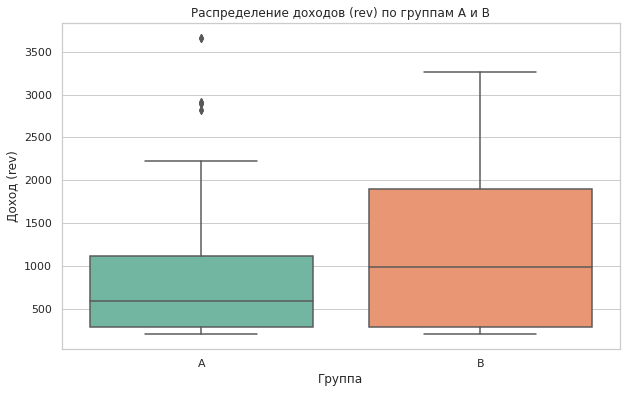

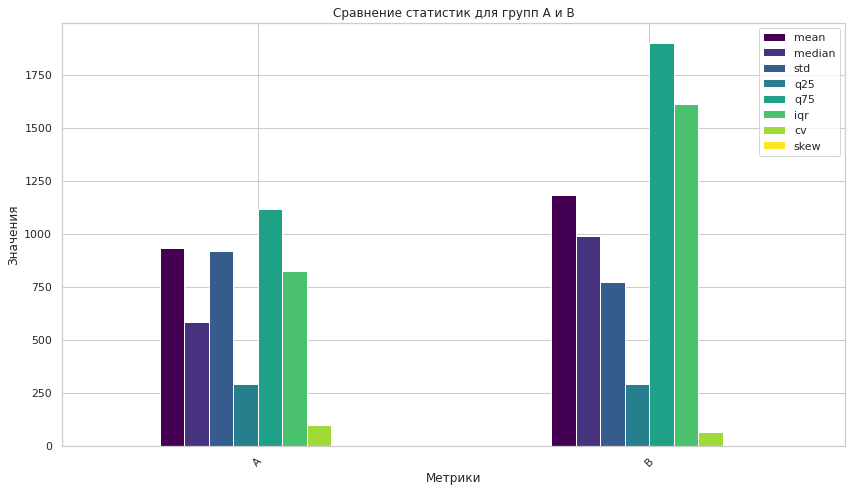

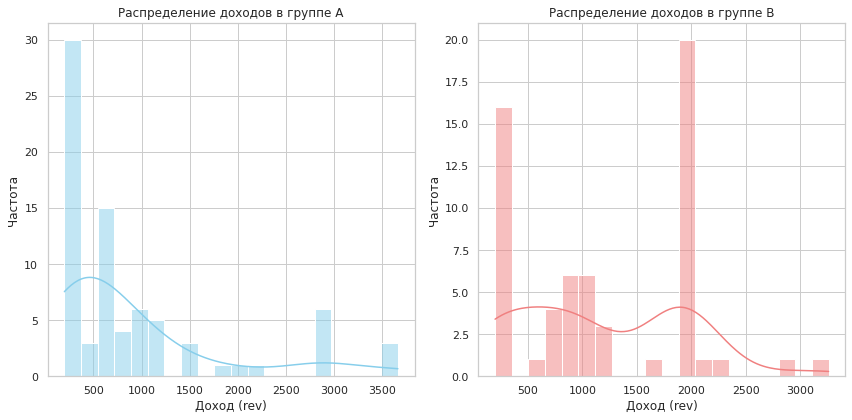

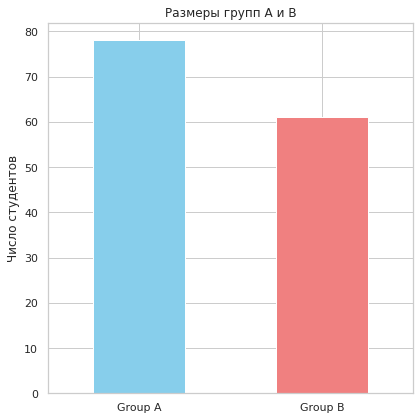

In [108]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
import time

%matplotlib inline

# ==================== Составление файловых путей ==================== 
student_login = 'il-kobzev'  
way = f'/mnt/HC_Volume_18315164/home-jupyter/jupyter-{student_login}/Final_Project'

def collect_all_csv_paths(way):
    csv_paths = []
    for root, _, files in os.walk(way):
        for filename in files:
            if filename.endswith('.csv'):  # Filter only CSV files
                absolute_file_path = os.path.join(root, filename)
                csv_paths.append(absolute_file_path)
    return csv_paths

# ==================== Функция обновления файла group_add ====================

def update_df_group_add(csv_path, df_group_add, last_checked):

    if not os.path.exists(csv_path):
        print(f"ОШИБКА: файл не существует {csv_path}")
        return df_group_add, last_checked

    file_mod_time = os.path.getmtime(csv_path)
    
   
    if file_mod_time > last_checked:
        print(f"Найдено обновление {csv_path}!")
        

        new_data = pd.read_csv(csv_path)

        updated_df_group_add = pd.concat([df_group_add, new_data]).drop_duplicates().reset_index(drop=True)

        return updated_df_group_add, file_mod_time
    else:
        print("Обновлений нет.")
        return df_group_add, last_checked

# ==================== Чтение датасетов из файлов ==================== 

csv_file_paths = collect_all_csv_paths(way)
print(f"Найдено {len(csv_file_paths)} CSV файлов:")
for path in csv_file_paths:
    print(f"  - {path}")

dataframes = {}
for csv_path in csv_file_paths:
    try:

        filename = os.path.basename(csv_path)
        filename_without_ext = os.path.splitext(filename)[0]
        
        df = pd.read_csv(csv_path)
       
        dataframes[filename_without_ext] = df
            
        var_name = filename_without_ext.replace('-', '_').replace(' ', '_').replace('.', '_')
        
        globals()[var_name] = df
        
        print(f"✓ Успешно прочтено: {filename} (shape: {df.shape}) доступен как: '{filename_without_ext}' в датафрейме и как переменная '{var_name}'")
        
    except Exception as e:
        print(f"✗ Обшибка чтения {os.path.basename(csv_path)}: {e}")

print(f"\nВсего df загружено: {len(dataframes)}")

# ==================== Подтверждение загрузки датафреймов ==================== 

print("\nAvailable DataFrames:")

for name, df in dataframes.items():
    print(f"  - {name}: {df.shape}")
df_groups = Проект_2_groups
df_checks = Проект_2_checks
df_active_studs = Проект_2_active_studs
df_group_add = Проект_2_group_add

# ==================== Periodic Check (Optional) ====================

# Initial setup for df_group_add update
csv_file_path = '/mnt/HC_Volume_18315164/home-jupyter/jupyter-il-kobzev/Final_Project/Проект_2_group_add.csv'  # Adjust with your actual path
last_checked_time = 0  # Initial timestamp

# Update df_group_add with new data from CSV if available
df_group_add, last_checked_time = update_df_group_add(csv_file_path, df_group_add, last_checked_time)

# ==================== DF 1 - Полный список студентов в группах в одном датафрейме (объединие df_groups и df_group_add)

# Create a new DataFrame from the original, keeping the original column

#создание копии оригинального df для избежания потери данных
df_groups1 = df_groups.copy()

# Разделение "слипшихся" столбцов id и grp
df_groups1[["id", "grp"]] = df_groups1['id;grp'].str.split(";", expand=True)

df_groups1["id"] = df_groups1["id"].astype("int64")
df_groups1["grp"] = df_groups1["grp"].astype("category")

df_groups2 = df_groups1.drop(("id;grp"), axis='columns')

# Удаление дубликатов и пропусков
df_groups3 = df_groups2.drop_duplicates().dropna()

# Объединение двух DF с группами студентов в один
df_groups_full = df_groups3.merge(df_group_add, on=["id", "grp"], how='outer')

df_groups_full = df_groups_full.rename(columns={'id': 'student_id'})

# ==================== DF2 - чеки (revenue)
df_checks1 = df_checks.copy()
df_checks1[["student_id", "rev"]] = df_checks1['student_id;"rev"'].str.split(";", expand=True)

# Convert types
df_checks1["student_id"] = df_checks1["student_id"].astype("int64")
df_checks1["rev"] = df_checks1["rev"].astype("float")

# Получаем датафрейм с разделением и нормальными названиями колонок (df_checks_clean)
df_checks_clean = df_checks1.drop('student_id;"rev"', axis=1)

# ==================== DF3 - Активные УЗ студентов на момент эксперимента
df_studsall = pd.merge(df_active_studs, df_groups_full, on="student_id", how="inner")

# 4. Равное количество студентов в группах A и B
count_A = df_studsall[df_studsall['grp'] == 'A'].shape[0]
count_B = df_studsall[df_studsall['grp'] == 'B'].shape[0]
df_B = df_studsall[df_studsall['grp'] == 'B'].sample(count_A, random_state=42)
df_studsall_cutb = pd.concat([df_studsall[df_studsall['grp'] == 'A'], df_B])
df_studsall_cutb = df_studsall_cutb.sample(frac=1, random_state=42).reset_index(drop=True)

# Присоединение чека (revenue)
df_studchecks = pd.merge(df_studsall_cutb, df_checks_clean, on="student_id", how="inner")

# Статистика
desc = df_studchecks.groupby('grp')['rev'].describe(percentiles=[0.25, 0.5, 0.75])
desc['sum'] = df_studchecks.groupby('grp')['rev'].sum()

# Расчет метрик
def calculate_metrics(group):
    return pd.Series({
        'count': group.count(),
        'mean': group.mean(),
        'median': group.median(),
        'std': group.std(),
        'sem': group.sem(),  # Стандартная ошибка среднего
        'sum': group.sum(),
        'min': group.min(),
        'max': group.max(),
        'q25': group.quantile(0.25),
        'q75': group.quantile(0.75),
        'iqr': group.quantile(0.75) - group.quantile(0.25),  # межквартильный размах
        'cv': (group.std() / group.mean() * 100 if group.mean() != 0 else np.nan),  # коэффициент вариации %
        'skew': group.skew(),  # коэффициент асимметрии
        'missing': group.isnull().sum()  # количество пропущенных значений
    })

# Применяем функцию
detailed_stats = df_studchecks.groupby('grp')['rev'].apply(calculate_metrics).unstack().round(2)
print(detailed_stats)

# Считаем проверяем размер групп
group_A = df_studchecks[df_studchecks['grp'] == 'A']['rev']
group_B = df_studchecks[df_studchecks['grp'] == 'B']['rev']

print(f"Размер группы A: {len(group_A)}")
print(f"Размер группы B: {len(group_B)}")

print("\n=== БИЗНЕС-МЕТРИКИ И ЭФФЕКТ РАЗМЕРА ===")

# Разница в средних
mean_diff = group_B.mean() - group_A.mean()
mean_diff_percent
# Set style for the plots
sns.set(style="whitegrid")

# ==================== Box Plot для распределения доходов по группам ====================
plt.figure(figsize=(10, 6))
sns.boxplot(x='grp', y='rev', data=df_studchecks, palette='Set2')
plt.title('Распределение доходов (rev) по группам A и B')
plt.ylabel('Доход (rev)')
plt.xlabel('Группа')
plt.show()

# ==================== Bar Plot для сравнения медиан, средних и других метрик ====================
# Группируем по 'grp' и выводим метрики
metrics = ['mean', 'median', 'std', 'q25', 'q75', 'iqr', 'cv', 'skew']

# Статистики для каждой группы
stats_for_plot = detailed_stats[metrics]

# Визуализация данных
stats_for_plot.plot(kind='bar', figsize=(12, 7), colormap='viridis')
plt.title('Сравнение статистик для групп A и B')
plt.ylabel('Значения')
plt.xlabel('Метрики')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==================== Гистограммы для распределения доходов в группах А и Б ====================
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(df_studchecks[df_studchecks['grp'] == 'A']['rev'], bins=20, kde=True, color='skyblue', label='Group A')
plt.title('Распределение доходов в группе A')
plt.xlabel('Доход (rev)')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
sns.histplot(df_studchecks[df_studchecks['grp'] == 'B']['rev'], bins=20, kde=True, color='lightcoral', label='Group B')
plt.title('Распределение доходов в группе B')
plt.xlabel('Доход (rev)')
plt.ylabel('Частота')

plt.tight_layout()
plt.show()

# ==================== Столбцовая диаграмма для визуализации размера групп ====================
group_sizes = pd.Series({
    'Group A': len(group_A),
    'Group B': len(group_B)
})

plt.figure(figsize=(6, 6))
group_sizes.plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.title('Размеры групп A и B')
plt.ylabel('Число студентов')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()